In [1]:
import os, getpass
os.environ["FIRMS_MAP_KEY"] = getpass.getpass("FIRMS MAP_KEY: ")

from fb_tools.active_fire import fetch_firms, apply_qa, firms_sources
firms_sources()

          source     satellite instrument  pixel_m latency
  VIIRS_SNPP_NRT   VIIRS S-NPP      VIIRS      375     NRT
   VIIRS_SNPP_SP   VIIRS S-NPP      VIIRS      375      SP
VIIRS_NOAA20_NRT VIIRS NOAA-20      VIIRS      375     NRT
 VIIRS_NOAA20_SP VIIRS NOAA-20      VIIRS      375      SP
VIIRS_NOAA21_NRT VIIRS NOAA-21      VIIRS      375     NRT
       MODIS_NRT         MODIS      MODIS     1000     NRT
        MODIS_SP         MODIS      MODIS     1000      SP
     LANDSAT_NRT       Landsat        OLI       30     NRT
        GOES_NRT          GOES        ABI     2000     NRT


,source,satellite,instrument,pixel_m,latency
0,VIIRS_SNPP_NRT,VIIRS S-NPP,VIIRS,375,NRT
1,VIIRS_SNPP_SP,VIIRS S-NPP,VIIRS,375,SP
2,VIIRS_NOAA20_NRT,VIIRS NOAA-20,VIIRS,375,NRT
3,VIIRS_NOAA20_SP,VIIRS NOAA-20,VIIRS,375,SP
4,VIIRS_NOAA21_NRT,VIIRS NOAA-21,VIIRS,375,NRT
5,MODIS_NRT,MODIS,MODIS,1000,NRT
6,MODIS_SP,MODIS,MODIS,1000,SP
7,LANDSAT_NRT,Landsat,OLI,30,NRT
8,GOES_NRT,GOES,ABI,2000,NRT


## 1. Example fire
WFIGS perimeter by name. `current` holds active fires only; use `year_to_date` or `history` once a fire is out.

In [2]:
import pandas as pd
from fb_tools.active_fire import (
    VIIRS_SP, fetch_wfigs_perimeters, associate_detections, assign_overpass, to_local,
    footprint_boxes, afd_grid, gridded_frp, first_detection_grid, to_raster,
)

TZ = "America/Denver"
fire = fetch_wfigs_perimeters("Aspen Acres", which="year_to_date")
fire = fire.sort_values("poly_PolygonDateTime").tail(1)          # latest perimeter if several match

START = pd.to_datetime(fire["attr_FireDiscoveryDateTime"], unit="ms", utc=True).iloc[0].date()
END = START + pd.Timedelta(days=14)                              # edit to the fire's active period
fire[["poly_IncidentName", "poly_GISAcres"]], START, END

WFIGS year_to_date: 1 perimeter(s)


(  poly_IncidentName  poly_GISAcres
 0       Aspen Acres  102003.460337,
 datetime.date(2026, 6, 29),
 datetime.date(2026, 7, 13))

## 2. Fetch
S-NPP and NOAA-20 from the Standard Product (has `type`, ends ~3 months back); NOAA-21 only exists as NRT. A second run is served from the cache.

In [3]:
SOURCES = [*VIIRS_SP, "VIIRS_NOAA21_NRT"]
det = fetch_firms(fire, START, END, sources=SOURCES, buffer_m=5000)
det.groupby(["satellite", "source"]).size()

[1/1] 8787 detections (0 requests, 45 source-days from cache)


satellite      source          
VIIRS NOAA-20  VIIRS_NOAA20_SP     2968
VIIRS NOAA-21  VIIRS_NOAA21_NRT    2951
VIIRS S-NPP    VIIRS_SNPP_SP       2868
dtype: int64

## 3. QA

In [4]:
kept, dropped = apply_qa(det)
dropped["qa_reason"].value_counts()

low confidence: dropped 743 of 8787
interscan duplicates: dropped 429 of 8044
static sources: 2505 detections have no `type` (NRT); not screened
static sources: dropped 0 of 7615


qa_reason
low_confidence    743
interscan         429
Name: count, dtype: int64

## 4. Keep detections on the fire
The fetch returns the bounding box; this clips to the perimeter + 1 km. Add `start_col` / `end_col` to filter by event dates.

In [5]:
afd = associate_detections(kept, fire, buffer_m=1000)
afd = assign_overpass(to_local(afd, TZ))

# one row per overpass: when, how many detections, total FRP
ops = afd.groupby(["overpass_id", "satellite"]).agg(
    time=("acq_local", "min"), n=("frp", "size"), frp_sum=("frp", "sum"), daynight=("daynight", "first"))
ops

associate: 7559 of 7615 detections matched to 1 event(s); 0 multi-event rows


,,time,n,frp_sum,daynight
overpass_id,satellite,,,,
0,VIIRS NOAA-20,2026-06-29 14:05:00-06:00,209,10296.43,D
1,VIIRS NOAA-20,2026-06-30 02:25:00-06:00,178,1791.82,N
2,VIIRS NOAA-20,2026-06-30 04:05:00-06:00,52,203.40,N
3,VIIRS NOAA-20,2026-06-30 13:46:00-06:00,4,58.19,D
4,VIIRS NOAA-20,2026-07-01 02:06:00-06:00,147,864.97,N
...,...,...,...,...,...
96,VIIRS S-NPP,2026-07-08 02:57:00-06:00,66,116.48,N
97,VIIRS S-NPP,2026-07-08 14:18:00-06:00,10,224.91,D
98,VIIRS S-NPP,2026-07-09 02:38:00-06:00,8,8.72,N


## 5. Footprints and grid
Scan x track boxes on a 480 m grid snapped to LANDFIRE pixel edges (`snap=` also takes a raster such as TreeMap).

In [6]:
boxes = footprint_boxes(afd)                                     # EPSG:5070, VIIRS only
grid = afd_grid(fire, res_m=480, snap="landfire")
boxes["pix_area_km2"].describe(), len(grid)

(count    7559.000000
 mean        0.247816
 std         0.114661
 min         0.136800
 25%         0.167200
 50%         0.211500
 75%         0.301600
 max         0.616200
 Name: pix_area_km2, dtype: float64,
 2105)

## 6. Gridded FRP
potr5 allocation (`frp_fr`). Day columns are local days with `tz=`.

gridded_frp: dropped 14 of 7559 detections with FRP <= 0 or missing


,afd_count,unique_days,overlap,frp_csum,frp_max,frp_p90,day_count,night_count
count,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000
mean,15.589414,2.041624,3.816225,430.939060,174.557552,71.991196,5.008736,10.580678
std,10.474868,1.346733,2.815542,539.521550,256.257486,108.979565,4.821698,8.890243
min,1.000000,1.000000,0.107134,0.207776,0.207776,0.207776,0.000000,0.000000
25%,8.000000,1.000000,1.702952,65.650687,22.256115,11.908292,1.000000,3.000000
50%,14.000000,2.000000,3.457193,229.598252,75.396054,32.876273,4.000000,10.000000
75%,21.000000,2.000000,5.102282,582.405523,219.300627,83.362475,8.000000,16.000000
max,81.000000,12.000000,25.127641,4437.418431,2724.457295,1050.703947,28.000000,76.000000


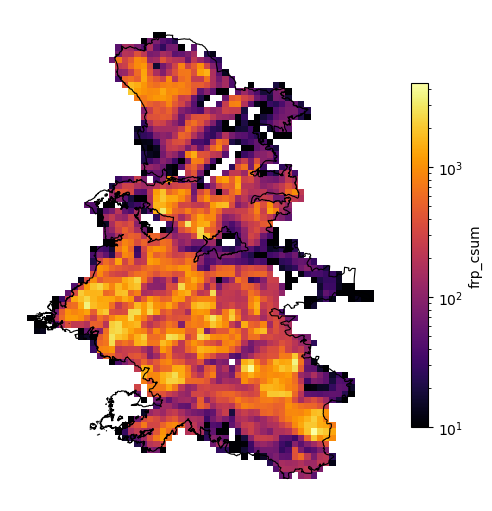

In [8]:
frp = gridded_frp(boxes, grid, tz=TZ)
frp = frp[frp["overlap"] >= 0.1] # filter low overlap

from fb_tools.active_fire import plot_grid
fig, ax = plot_grid(frp, "frp_csum", scale="log", vmin=10, events=fire)   # scale: "linear" | "log" | "sqrt"
frp[["afd_count", "unique_days", "overlap", "frp_csum", "frp_max", "frp_p90", "day_count", "night_count"]].describe()

## 7. First detection
Default: earliest overpass whose boxes cover >= 50% of the cell. `any` is the potr5 rule; `centre` uses the detection centre.

{'fraction': 1773, 'any': 2002, 'centre': 1746}

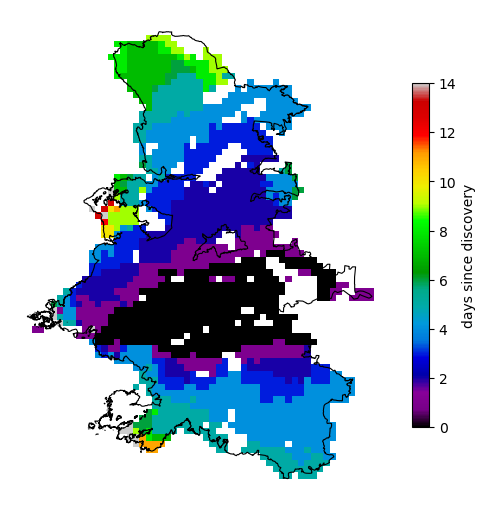

In [14]:
first = first_detection_grid(boxes, grid)                        # rule="fraction", min_fraction=0.5
first["day"] = (first["first_detection"].dt.tz_convert(TZ).dt.normalize()
                - pd.Timestamp(START, tz=TZ)).dt.days

fig, ax = plot_grid(first, "day", cmap="nipy_spectral", events=fire, label="days since discovery")

# how much the rule matters: cells detected, and area by day
{r: len(first_detection_grid(boxes, grid, rule=r)) for r in ("fraction", "any", "centre")}

In [11]:
# detected area per day (km2), under the default rule
first.groupby("day").size().mul(0.48 ** 2).rename("km2")

day
0     79.9488
1     44.0064
2     59.4432
3     45.1584
4     92.3904
5     43.7760
6      5.9904
7     14.5152
8      7.3728
9      8.7552
10     1.1520
11     1.8432
12     0.2304
13     0.6912
14     3.2256
Name: km2, dtype: float64

## 8. Export

In [12]:
from pathlib import Path
OUT = Path("out"); OUT.mkdir(exist_ok=True)

to_raster(frp, "frp_csum", OUT / "aspen_acres_frp_csum.tif")
to_raster(first, "first_detection", OUT / "aspen_acres_first_detection.tif", t0=START)   # days since START (UTC)
afd.drop(columns="acq_local").to_file(OUT / "aspen_acres_afd.gpkg", layer="detections")

## Other calls worth trying
- `firms_sources(map_key=os.environ["FIRMS_MAP_KEY"])` - live date range per source.
- `fetch_firms(..., sources=["MODIS_SP"])` or `["GOES_NRT"]` - other sensors, kept separate (FRP is not comparable).
- `apply_qa(det, low_conf=False)` and `remove_interscan_duplicates(det, radius_m=375)` - QA sensitivity.
- `footprint_boxes(afd[afd.satellite == "VIIRS NOAA-20"])` then `gridded_frp` - one satellite at a time.
- `afd_grid(fire, res_m=480, snap="path/to/TreeMap2016.tif")` - cells nested in a reference raster.
- `first_detection_grid(boxes, grid, min_fraction=0.25, gap_min=15)` - threshold and overpass-gap sensitivity.
- `map_events(func, det, events, id_col=...)` after a multi-fire `fetch_firms(events, id_col=..., start_col=..., end_col=...)`.